<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/09_activation-functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 9: Modeling Probabilities and Nonlinearities
## Activation functions

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

This notebook covers what an activation function is, the four constraints that make a good one, the standard hidden/output activations (sigmoid, tanh, softmax), how to "install" one in forward and backward passes, and the final upgraded MNIST network from the book. Several small experiments of my own check the claims numerically.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

x = np.linspace(-6, 6, 400)
relu_f    = lambda v: (v > 0) * v
sigmoid_f = lambda v: 1 / (1 + np.exp(-v))
tanh_f    = np.tanh

---
## What is an activation function?

An **activation function** is a function applied to the neurons of a layer **during prediction**. You have already used one: **relu** (turn negative numbers into 0) on the hidden layer of the three-layer network. Oversimplified, it is any function that takes one number and returns another. But infinitely many functions exist and most make terrible activations, so there are constraints.

---
## Constraint 1: the function must be continuous and infinite in domain

It must produce an output for **any** input. A function defined only at a few isolated points is useless: most inputs have no output. `y = x * x` is fine, since every `x` has a `y`.

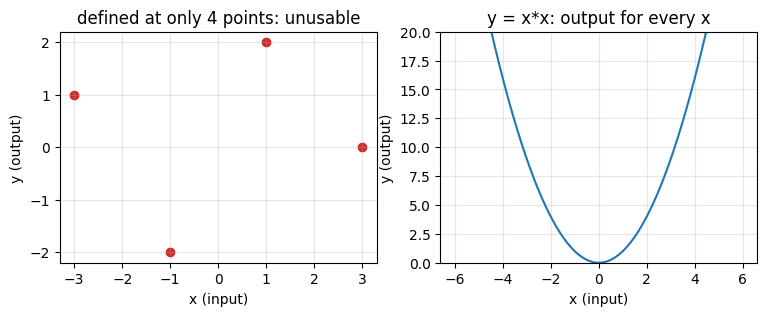

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
px = np.array([-3, -1, 1, 3]); ax[0].scatter(px, [1, -2, 2, 0], color="C3"); ax[0].set_title("defined at only 4 points: unusable")
ax[1].plot(x, x * x); ax[1].set_title("y = x*x: output for every x"); ax[1].set_ylim(0, 20)
for a in ax: a.grid(alpha=.3); a.set_xlabel("x (input)"); a.set_ylabel("y (output)")
plt.show()

---
## Constraint 2: good activation functions are monotonic

They should **never change direction**: always increasing (or always decreasing), so different inputs give different outputs. If several inputs map to the same output (like `x*x`, where −2 and 2 both give 4), the network has multiple "perfect" weight configurations, and then there may be no clear direction in which to reduce the error. (The book notes this isn't a strict requirement, since non-monotonic functions *can* be optimised, but it makes learning harder.)

In [3]:
f = lambda v: v * v
print("x*x at -2 and +2:", f(-2), f(2), "  -> two inputs, one output (not 1:1)")
g = lambda v: v
print("x   at -2 and +2:", g(-2), g(2), "  -> every input has its own output")

x*x at -2 and +2: 4 4   -> two inputs, one output (not 1:1)
x   at -2 and +2: -2 2   -> every input has its own output


---
## Constraint 3: good activation functions are nonlinear

They must **squiggle or turn**. A straight line only *scales* the incoming weighted sum, which makes the neuron "louder or softer" but never lets one input change **how much the neuron cares about the other inputs**. This is the *sometimes correlation* from Chapter 6: a very negative signal from one input should be able to switch the neuron off regardless of the rest (relu does this by forcing the value to 0).

There is a sharp way to see why linearity is fatal: **two stacked linear layers collapse into one**.

In [4]:
rng = np.random.RandomState(0)
inp = rng.randn(1, 3)
W0, W1 = rng.randn(3, 4), rng.randn(4, 2)

two_linear_layers = inp.dot(W0).dot(W1)
one_linear_layer  = inp.dot(W0.dot(W1))
with_relu         = relu_f(inp.dot(W0)).dot(W1)

print("two linear layers      :", two_linear_layers.round(4))
print("ONE layer (W0 @ W1)    :", one_linear_layer.round(4), " <- identical:", np.allclose(two_linear_layers, one_linear_layer))
print("with relu in between   :", with_relu.round(4), " <- different: no single matrix can imitate it")

two linear layers      : [[ 3.601  14.7459]]
ONE layer (W0 @ W1)    : [[ 3.601  14.7459]]  <- identical: True
with relu in between   : [[ 2.3706 11.0681]]  <- different: no single matrix can imitate it


Without a nonlinearity the extra layer adds **nothing**. Only the bend in relu (or sigmoid/tanh) lets a deep network do more than a single matrix.

---
## Constraint 4: good activation functions (and their derivatives) are efficiently computable

You call the function billions of times, so it must be cheap. Many modern activations are popular precisely because they are cheap (relu is the classic example). A quick measurement on 1 million numbers:

In [5]:
big = np.random.randn(1_000_000)
def timeit(fn, reps=20):
    t0 = time.perf_counter()
    for _ in range(reps): fn(big)
    return (time.perf_counter() - t0) / reps * 1000

for name, fn in [("relu", lambda v: np.maximum(v, 0)), ("sigmoid", lambda v: 1 / (1 + np.exp(-v))), ("tanh", np.tanh)]:
    print(f"{name:8s}: {timeit(fn):6.2f} ms per 1,000,000 values")

relu    :   2.40 ms per 1,000,000 values


sigmoid :   9.19 ms per 1,000,000 values


tanh    :   2.87 ms per 1,000,000 values


---
## Standard hidden-layer activation functions

- **sigmoid**: the bread-and-butter activation. It squishes any input smoothly into **(0, 1)**, so you can read a neuron's output as a probability. Used in hidden and output layers.
- **tanh**: the same S-shape but **between −1 and 1**, so a neuron can express *negative* correlation as well as positive. Often better than sigmoid in hidden layers, but less useful for outputs (unless the targets lie in −1 to 1).

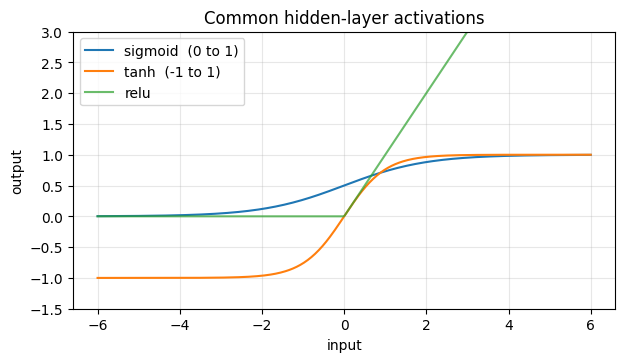

In [6]:
plt.figure(figsize=(7, 3.6))
plt.plot(x, sigmoid_f(x), label="sigmoid  (0 to 1)")
plt.plot(x, tanh_f(x),    label="tanh  (-1 to 1)")
plt.plot(x, relu_f(x),    label="relu", alpha=.7)
plt.ylim(-1.5, 3); plt.xlabel("input"); plt.ylabel("output"); plt.title("Common hidden-layer activations")
plt.legend(); plt.grid(alpha=.3); plt.show()

---
## Standard output-layer activation functions

What's best for hidden layers differs from what's best for the output, and it depends on **what you're predicting**. Three main cases:

| Configuration | Use when | Activation |
|---|---|---|
| **1. Raw data values** | the output is any number (e.g. temperature in Colorado from neighbouring states); least common | **none** (sigmoid/tanh would clamp the range wrongly) |
| **2. Unrelated yes/no probabilities** | several independent binary predictions (win? hurt? sad?) | **sigmoid**: each output is modelled separately |
| **3. Which-one probabilities** | exactly one label out of many (MNIST digit) | **softmax** |

A side benefit of predicting several things at once with a hidden layer: what the network learns for one label can help another.

**Why softmax for 'which one'?** The book's thought experiment: the raw outputs for an image of a 9 are `0` everywhere except `100` for the 9. Let's see what each activation says:

In [7]:
raw = np.array([0.0] * 9 + [100.0])
target = np.array([0.0] * 9 + [1.0])           # the image really is a 9

def softmax_vec(v):
    e = np.exp(v - v.max())                    # subtracting the max avoids overflow; result is unchanged
    return e / e.sum()

sig, soft = sigmoid_f(raw), softmax_vec(raw)
print("sigmoid:", sig.round(2))
print("softmax:", soft.round(2))
print()
print("per-node squared error, sigmoid:", ((sig - target) ** 2).round(2))
print("total squared error, sigmoid   :", ((sig - target) ** 2).sum().round(2))
print("total squared error, softmax   :", ((soft - target) ** 2).sum().round(2))

sigmoid: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1. ]
softmax: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]

per-node squared error, sigmoid: [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.  ]
total squared error, sigmoid   : 2.25
total squared error, softmax   : 0.0


Even though the network is *perfect* (it put all its weight on the 9), **sigmoid** still outputs 0.5 for all the wrong digits, so the error is 0.25 on each of them and the network would receive a **big weight update despite predicting perfectly**. To reach zero error sigmoid must not only favour 9 but also push every other digit's *independent* probability to 0. **Softmax** asks the better question, "which digit fits best?", and says "9, and nothing else".

---
## The core issue: inputs have similarity

Different digits share pixels. The average 2 has a lot in common with the average 3 (the curve at the top), and **similar inputs create similar outputs**. If a 2 accidentally gives a little probability to "3", a sigmoid/MSE network treats that as a big mistake and punishes the network for recognising a 2 by its top curve, because that curve also appears in 3s. The network then learns to rely on exclusive features (mostly at the edges) instead of the whole shape.

We want an output that doesn't penalise labels for being similar. Softmax also makes the outputs **sum to 1**, so each is a global probability.

**My demo: measure the similarity between digits** with the cosine of the *average image* of each class.

### Loading MNIST
The book calls `keras.datasets.mnist` (preinstalled on Colab). The cell below does exactly that, and **falls back to downloading the same MNIST data from a public GitHub mirror** if Keras isn't available, so the notebook also runs outside Colab. As in the book, we train on only the **first 1,000 images** and test on the standard **10,000 test images**. I also keep images 1,000–1,999 as a *validation set* (used for early stopping later).

In [8]:
import sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt

def load_mnist():
    try:
        from keras.datasets import mnist                      # what the book uses
        (x_train, y_train), (x_test, y_test) = mnist.load_data()
        x_train = x_train.reshape(len(x_train), 784) / 255
        x_test  = x_test.reshape(len(x_test), 784) / 255
    except Exception:                                         # fallback: same dataset from a GitHub mirror
        import gzip, pickle, os, urllib.request
        url = "https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz"
        if not os.path.exists("mnist.pkl.gz"):
            urllib.request.urlretrieve(url, "mnist.pkl.gz")
        with gzip.open("mnist.pkl.gz", "rb") as f, warnings.catch_warnings():
            warnings.simplefilter("ignore")
            train, valid, test = pickle.load(f, encoding="latin1")
        x_train, y_train = train[0].astype("float64"), train[1]
        x_test,  y_test  = test[0].astype("float64"),  test[1]

    def one_hot(y):
        out = np.zeros((len(y), 10))
        out[np.arange(len(y)), y] = 1
        return out

    images,      labels      = x_train[0:1000],    one_hot(y_train[0:1000])
    val_images,  val_labels  = x_train[1000:2000], one_hot(y_train[1000:2000])
    test_images, test_labels = x_test,             one_hot(y_test)
    return images, labels, val_images, val_labels, test_images, test_labels

images, labels, val_images, val_labels, test_images, test_labels = load_mnist()
print("train :", images.shape, labels.shape)
print("val   :", val_images.shape)
print("test  :", test_images.shape, test_labels.shape)
print("first labels:", labels[:10].argmax(axis=1))

train : (1000, 784) (1000, 10)
val   : (1000, 784)
test  : (10000, 784) (10000, 10)
first labels: [5 0 4 1 9 2 1 3 1 4]


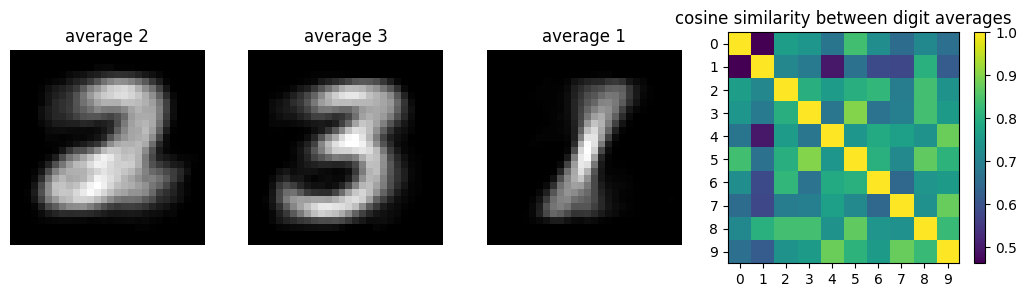

similarity 2 vs 3: 0.801    2 vs 1: 0.712
every pair of digit averages has similarity at least 0.46


In [9]:
means = np.array([images[labels.argmax(1) == d].mean(axis=0) for d in range(10)])
unit  = means / np.linalg.norm(means, axis=1, keepdims=True)
cos   = unit.dot(unit.T)

fig, ax = plt.subplots(1, 4, figsize=(13, 3), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
for a, d in zip(ax[:3], (2, 3, 1)):
    a.imshow(means[d].reshape(28, 28), cmap="gray"); a.set_title(f"average {d}"); a.axis("off")
im = ax[3].imshow(cos, cmap="viridis"); ax[3].set_title("cosine similarity between digit averages")
ax[3].set_xticks(range(10)); ax[3].set_yticks(range(10)); plt.colorbar(im, ax=ax[3]); plt.show()

print("similarity 2 vs 3:", cos[2, 3].round(3), "   2 vs 1:", cos[2, 1].round(3))
print("every pair of digit averages has similarity at least", cos[~np.eye(10, dtype=bool)].min().round(2))

Even different digits are strongly similar (every pair of averages has cosine similarity above 0.45 here), so an output layer that punishes similarity fights the data. That's the case for softmax.

---
## softmax computation

**softmax raises each input exponentially and divides by the layer's sum.**

1. Compute `e^x` for each raw value (all the 0s become 1; the 100 becomes ≈ 2.7 × 10⁴³; negatives become small positives).
2. Divide each by the sum of all of them.

The higher the network scores one value, the lower every other probability gets (sharper *attenuation*). Using a base larger or smaller than *e* makes it more or less aggressive, but everyone uses *e*.

In [10]:
def softmax(x):                                # the book's version, written for batches (rows)
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)

row = raw.reshape(1, -1)
print("e^100 =", np.exp(100.0))
print("softmax of the book's example:", softmax(row).round(3))

scores = np.array([[1.0, 2.0, 3.0]])
for base in (1.5, np.e, 10):
    p = base ** scores / np.sum(base ** scores)
    print(f"base {base:5.2f}: {p.round(3)}")

big_scores = np.array([[1000.0, 1001.0]])
with np.errstate(all="ignore"):
    print("naive softmax with scores near 1000 ->", softmax(big_scores))
print("max-subtracted version               ->", np.exp(big_scores - big_scores.max()) / np.exp(big_scores - big_scores.max()).sum())

e^100 = 2.6881171418161356e+43
softmax of the book's example: [[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]
base  1.50: [[0.211 0.316 0.474]]
base  2.72: [[0.09  0.245 0.665]]
base 10.00: [[0.009 0.09  0.901]]
naive softmax with scores near 1000 -> [[nan nan]]
max-subtracted version               -> [[0.26894142 0.73105858]]


A larger base sharpens the distribution; a smaller one flattens it. Also note a practical hazard the book doesn't mention: with very large scores the naive formula overflows to `nan`. Subtracting the maximum first gives the same probabilities and is what libraries do.

---
## Activation installation instructions

**Forward propagation** is easy: apply the function to the layer's *input* (the value before the nonlinearity):

```python
layer_1 = relu(np.dot(layer_0, weights_0_1))
```

**Backpropagation** needs one more step. In Chapter 6 we zeroed `layer_1_delta` wherever relu had zeroed `layer_1`. That's the extreme version of a more general rule: **multiply the incoming delta by the slope (derivative) of the activation at the point that was predicted.** relu's slope is exactly 1 for positive inputs and 0 for negative ones; its slope says how much a tiny change of the input would change the output.

```python
layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
```

---
## Multiplying delta by the slope

`layer_1_delta[0]` says how much higher or lower hidden node 0 should be. The goal of that delta is to tell the weights *whether they should move*. If moving them would have little effect, the group should be **left alone**. For relu that's on/off. For **sigmoid** the sensitivity is greatest near 0 and fades to nearly 0 for very positive or very negative inputs.

Two consequences from the book: nodes irrelevant to this example (maybe used only for 8s) aren't disturbed, and there's a kind of **stickiness**: weights that have confidently pushed a node far in one direction are hard for an occasional odd example to corrupt.

input -6: sigmoid output 0.002   slope 0.0025
input -2: sigmoid output 0.119   slope 0.1050
input  0: sigmoid output 0.500   slope 0.2500
input  2: sigmoid output 0.881   slope 0.1050
input  6: sigmoid output 0.998   slope 0.0025


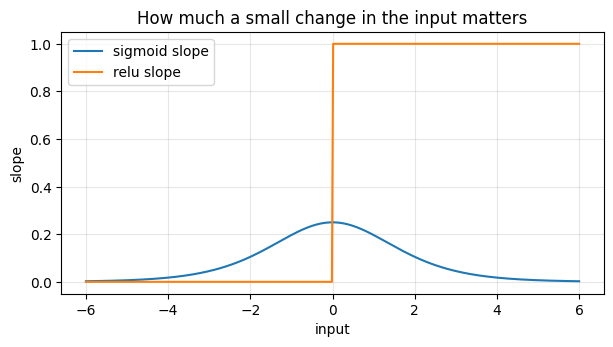

In [11]:
slope_sigmoid = lambda v: sigmoid_f(v) * (1 - sigmoid_f(v))
for v in (-6, -2, 0, 2, 6):
    print(f"input {v:>2}: sigmoid output {sigmoid_f(v):.3f}   slope {slope_sigmoid(v):.4f}")

plt.figure(figsize=(7, 3.4))
plt.plot(x, slope_sigmoid(x), label="sigmoid slope")
plt.plot(x, (x > 0).astype(float), label="relu slope")
plt.xlabel("input"); plt.ylabel("slope"); plt.title("How much a small change in the input matters"); plt.legend(); plt.grid(alpha=.3); plt.show()

---
## Converting output to slope (derivative)

Efficiency trick: the popular activations can compute their slope **from their own output** (already available from forward propagation), so no extra calculus at runtime. The book's table:

| Function | Forward | Slope computed from the *output* |
|---|---|---|
| relu | `output = input * (input > 0)` | `output > 0` |
| sigmoid | `1 / (1 + np.exp(-input))` | `output * (1 - output)` |
| tanh | `np.tanh(input)` | `1 - output**2` |
| softmax | `exp(input) / sum(exp(input))` | delta `(output - true)` (used only at the last layer) |

Let's **verify each formula numerically** (my addition) against a finite-difference slope.

In [12]:
def numeric_slope(f, v, h=1e-6):
    return (f(v + h) - f(v - h)) / (2 * h)

pts = np.array([-2.0, -0.5, 0.3, 1.7])
checks = {
    "relu"   : (relu_f,    lambda out: (out > 0) * 1.0),
    "sigmoid": (sigmoid_f, lambda out: out * (1 - out)),
    "tanh"   : (tanh_f,    lambda out: 1 - out ** 2),
}
for name, (f, slope_from_output) in checks.items():
    out = f(pts)
    diff = np.max(np.abs(slope_from_output(out) - numeric_slope(f, pts)))
    print(f"{name:8s}: max |formula - numeric slope| = {diff:.2e}")

# softmax + cross-entropy: gradient of the loss w.r.t. the raw scores equals (output - true)
z = np.array([0.2, -1.0, 0.7, 0.1]); true = np.array([0, 0, 1, 0])
p = np.exp(z) / np.exp(z).sum()
ce = lambda zz: -np.sum(true * np.log(np.exp(zz) / np.exp(zz).sum()))
num = np.array([(ce(z + h) - ce(z - h)) / 2e-6 for h in np.eye(4) * 1e-6 * 1])
print("softmax + cross-entropy: (output - true) =", (p - true).round(5))
print("                  numeric gradient       =", num.round(5))

relu    : max |formula - numeric slope| = 8.23e-11
sigmoid : max |formula - numeric slope| = 2.90e-11
tanh    : max |formula - numeric slope| = 3.34e-11
softmax + cross-entropy: (output - true) = [ 0.25942  0.07814 -0.57229  0.23473]
                  numeric gradient       = [ 0.25942  0.07814 -0.57229  0.23473]


All three slope-from-output formulas match the numeric slope, and for softmax the gradient of the cross-entropy loss with respect to the raw scores is exactly `output - true`. That is why the book's `layer_2_delta` for the softmax layer is just *(target − prediction)*, with no extra slope factor. (Softmax is *meant* to be paired with **cross-entropy** error. The book leaves the error calculation out for now, because it hasn't yet explained why cross-entropy is the right measure.)

---
## Upgrading the MNIST network

Theory says **tanh** should beat relu in the hidden layer, and **softmax** should beat a linear output. Applying them takes a few adjustments, as the author notes:

- **Narrower weight initialisation for tanh:** `0.02 * random - 0.01` (between −0.01 and 0.01) instead of ±0.1.
- **A much higher alpha** (here 2) to reach a good score in 300 iterations. Every change to a network means revisiting alpha.
- **No error calculation** (see above). I additionally log the cross-entropy on the test set as a sanity check.

One detail about the book's code: `layer_2_delta = (labels - layer_2) / (batch_size * layer_2.shape[0])`. Here `layer_2.shape[0]` *is* the batch size, so the delta is effectively divided by `batch_size²` = 10,000, which is part of why a large alpha is needed.

In [13]:
np.random.seed(1)

def tanh(x):        return np.tanh(x)
def tanh2deriv(output): return 1 - (output ** 2)

alpha, iterations, hidden_size = (2, 300, 100)
pixels_per_image, num_labels = (784, 10)
batch_size = 100

weights_0_1 = 0.02 * np.random.random((pixels_per_image, hidden_size)) - 0.01
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

log = {"it": [], "train_acc": [], "test_acc": [], "test_ce": []}
t0 = time.time()
for j in range(iterations):
    correct_cnt = 0
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))

        layer_0 = images[batch_start:batch_end]
        layer_1 = tanh(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        correct_cnt += int(np.sum(np.argmax(layer_2, axis=1) == np.argmax(labels[batch_start:batch_end], axis=1)))

        layer_2_delta = (labels[batch_start:batch_end] - layer_2) / (batch_size * layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if j % 10 == 0 or j == iterations - 1:
        probs = softmax(tanh(test_images.dot(weights_0_1)).dot(weights_1_2))
        test_acc = np.mean(probs.argmax(1) == test_labels.argmax(1))
        test_ce  = -np.mean(np.sum(test_labels * np.log(probs + 1e-12), axis=1))
        log["it"].append(j); log["train_acc"].append(correct_cnt / len(images)); log["test_acc"].append(test_acc); log["test_ce"].append(test_ce)
        print(f"I:{j:3d} Test-Acc:{test_acc:.4f} Train-Acc:{correct_cnt/len(images):.3f}  (test cross-entropy {test_ce:.3f})")
print(f"\nlayer_2.shape[0] == batch_size ? {layer_2.shape[0] == batch_size};  total time {time.time()-t0:.1f}s")

I:  0 Test-Acc:0.3925 Train-Acc:0.156  (test cross-entropy 2.269)


I: 10 Test-Acc:0.6864 Train-Acc:0.723  (test cross-entropy 1.927)


I: 20 Test-Acc:0.7019 Train-Acc:0.733  (test cross-entropy 1.539)


I: 30 Test-Acc:0.7329 Train-Acc:0.762  (test cross-entropy 1.237)


I: 40 Test-Acc:0.7655 Train-Acc:0.794  (test cross-entropy 1.036)


...

I:230 Test-Acc:0.8671 Train-Acc:0.937  (test cross-entropy 0.448)
I:240 Test-Acc:0.8680 Train-Acc:0.938  (test cross-entropy 0.443)


I:250 Test-Acc:0.8685 Train-Acc:0.937  (test cross-entropy 0.439)
I:260 Test-Acc:0.8687 Train-Acc:0.945  (test cross-entropy 0.436)


I:270 Test-Acc:0.8702 Train-Acc:0.951  (test cross-entropy 0.431)


I:280 Test-Acc:0.8699 Train-Acc:0.949  (test cross-entropy 0.429)


I:290 Test-Acc:0.8702 Train-Acc:0.940  (test cross-entropy 0.426)
I:299 Test-Acc:0.8705 Train-Acc:0.953  (test cross-entropy 0.424)

layer_2.shape[0] == batch_size ? True;  total time 6.2s


The upgraded network reaches about **87% test accuracy**. As a comparison, here is the relu + dropout + batch network from Chapter 8 (same data, same batch size):

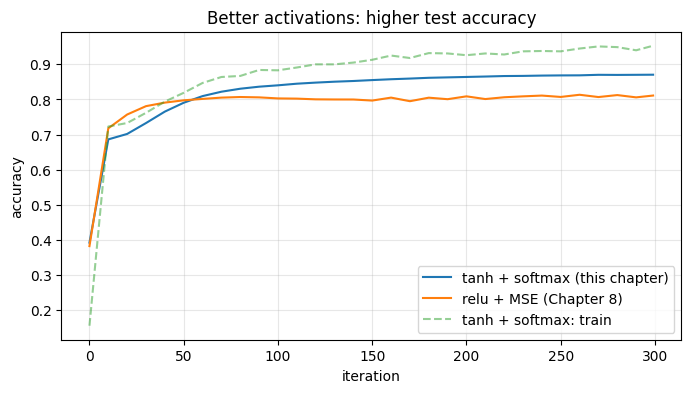

tanh + softmax final test accuracy: 0.8705   |   relu + MSE final test accuracy: 0.8112


In [14]:
np.random.seed(1)
relu = lambda v: (v >= 0) * v
relu2deriv = lambda v: v >= 0
w01 = 0.2 * np.random.random((784, 100)) - 0.1
w12 = 0.2 * np.random.random((100, 10)) - 0.1
ch8 = {"it": [], "test_acc": []}
for j in range(300):
    for i in range(10):
        l0 = images[i*100:(i+1)*100]; l1 = relu(l0.dot(w01)); m = np.random.randint(2, size=l1.shape); l1 *= m * 2
        l2 = l1.dot(w12); d2 = (labels[i*100:(i+1)*100] - l2) / 100
        d1 = d2.dot(w12.T) * relu2deriv(l1) * m
        w12 += 0.1 * l1.T.dot(d2); w01 += 0.1 * l0.T.dot(d1)
    if j % 10 == 0 or j == 299:
        ch8["it"].append(j); ch8["test_acc"].append(np.mean(relu(test_images.dot(w01)).dot(w12).argmax(1) == test_labels.argmax(1)))

plt.figure(figsize=(8, 4))
plt.plot(log["it"], log["test_acc"], label="tanh + softmax (this chapter)")
plt.plot(ch8["it"], ch8["test_acc"], label="relu + MSE (Chapter 8)")
plt.plot(log["it"], log["train_acc"], "--", alpha=.5, label="tanh + softmax: train")
plt.xlabel("iteration"); plt.ylabel("accuracy"); plt.title("Better activations: higher test accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"tanh + softmax final test accuracy: {log['test_acc'][-1]:.4f}   |   relu + MSE final test accuracy: {ch8['test_acc'][-1]:.4f}")

---
## Summary

- An **activation function** transforms each neuron's weighted sum during prediction. A good one is **continuous, (ideally) monotonic, nonlinear, and cheap**.
- **Hidden layers**: relu, sigmoid, or **tanh** (which allows negative correlation).
- **Output layers**: *none* for raw values, **sigmoid** for independent yes/no outputs, **softmax** for "which one" outputs.
- Forward pass: apply the function. Backward pass: **multiply the incoming delta by the function's slope**, usually computed from the layer's *output*.
- Changing activations means retuning **weight initialisation and alpha**.